In [1]:
import pandas as pd
import scanpy as sc
import sys
from pathlib import Path
import numpy as np
from scipy.stats import f_oneway

In [2]:
# Add the IDEAS repo root to Python's import path
repo_root = Path("/home/csb/Saloni/IDEAS_ID/IDEAS")
sys.path.append(str(repo_root))

from computeID.functions_IDEAS import compute_ID

/home/csb/Saloni/IDEAS_ID/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [14]:
adata = sc.read('/home/csb/Saloni/IDEAS_ID/IDEAS/Data/DU145_EGF.h5ad')

print(adata)

AnnData object with n_obs × n_vars = 4663 × 13811
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'percent.mito', 'Sample', 'CellLine', 'Treatment', 'Time', 'Doublet', 'S.Score', 'G2M.Score', 'Phase', 'Mix', 'SCT_snn_res.0.8', 'SCT_snn_res.0.1', 'RNA_snn_res.0.1', 'seurat_clusters', 'RNA_snn_res.0.05', 'Cluster', 'RNA_snn_res.0.5', 'Pseudotime'


In [15]:
id_local = compute_ID(
    adata,
    group="all",
    method="local_2nn",
    n_neighbors=50,
    normalization=True,
    full_output=True,
    id_score=True
)

print(id_local.shape)

Computing Intrinsic Dimension:   0%|          | 0/1 [00:00<?, ?it/s]

Computing ID:


Computing Intrinsic Dimension: 100%|██████████| 1/1 [00:28<00:00, 28.65s/it]

(4663, 1)


In [16]:
id_results = compute_ID(
    adata,
    group="Time",
    method="2nn",
    n_samples=30,
    sample_size=0,
    normalization=True,
    full_output=True,
    id_score=True
)

/home/csb/Saloni/IDEAS_ID/IDEAS/computeID/functions_IDEAS.py:41: UserWarning: 'sample_size' not specified: automatically set to 274 (80% of smallest group size: 4663)
  warnings.warn(f"'sample_size' not specified: automatically set to {sample_size} (80% of smallest group size: {n_obs})")
Computing Intrinsic Dimension:   0%|          | 0/8 [00:00<?, ?it/s]

Computing ID for Time 0d:


Computing Intrinsic Dimension:  12%|█▎        | 1/8 [00:01<00:08,  1.26s/it]

Computing ID for Time 1d:


Computing Intrinsic Dimension:  25%|██▌       | 2/8 [00:02<00:07,  1.28s/it]

...

Computing Intrinsic Dimension:  75%|███████▌  | 6/8 [00:07<00:02,  1.26s/it]

Computing ID for Time 8h:


Computing Intrinsic Dimension:  88%|████████▊ | 7/8 [00:08<00:01,  1.26s/it]

Computing ID for Time 8h_rm:


Computing Intrinsic Dimension: 100%|██████████| 8/8 [00:10<00:00,  1.26s/it]


In [17]:
print(id_results.shape)
display(id_results.head())

print(id_local.shape)
print(id_local.head())

(30, 8)


,0d,1d,1d_rm,3d,3d_rm,7d,8h,8h_rm
1,0.280859,0.387029,0.601006,0.715355,0.645497,0.335998,0.684910,0.366761
2,0.333664,0.562853,0.910069,0.449692,0.479305,0.424899,0.203669,0.434242
3,0.364430,0.269598,0.253285,0.337984,0.571287,1.000000,0.396302,0.431534
4,0.292922,0.496814,0.544949,0.463741,0.424578,0.763373,0.612472,0.205899
5,0.258982,0.344813,0.457430,0.525376,0.105525,0.537001,0.606532,0.362648


(4663, 1)
                             ID
Mix1_AAAGATGCACTATCTT  0.349284
Mix1_AAAGCAAAGCCAGTAG  0.302264
Mix1_AACCGCGAGATCCCAT  0.366732
Mix1_AACGTTGAGTGAACGC  0.240619
Mix1_AACGTTGCAAGACACG  0.512438


In [18]:
id_summary = pd.DataFrame({
    "Time": id_results.columns,
    "ID": id_results.mean(axis=0),
    "SD": id_results.std(axis=0)
})

display(id_summary)

id_local_df = id_local.copy()

id_local_df.index.name = "cell"

id_local_df.to_excel(
    "/home/csb/Saloni/SCENT/data/ID/DU145_EGF_ID_local.xlsx"
)

print(id_local_df.head())

,Time,ID,SD
0d,0d,0.239570,0.118855
1d,1d,0.432296,0.193360
1d_rm,1d_rm,0.460828,0.193416
3d,3d,0.341929,0.208358
3d_rm,3d_rm,0.401972,0.138723
7d,7d,0.442142,0.165874
8h,8h,0.461559,0.170993
8h_rm,8h_rm,0.464524,0.158298


                             ID
Mix1_AAAGATGCACTATCTT  0.349284
Mix1_AAAGCAAAGCCAGTAG  0.302264
Mix1_AACCGCGAGATCCCAT  0.366732
Mix1_AACGTTGAGTGAACGC  0.240619
Mix1_AACGTTGCAAGACACG  0.512438


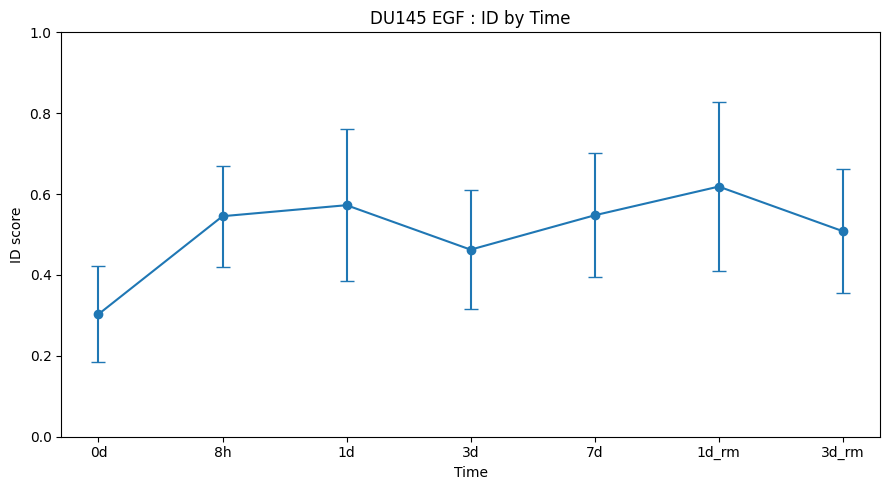

In [28]:
import matplotlib.pyplot as plt

time_order = ["0d", "8h", "1d", "3d", "7d", "1d_rm", "3d_rm"]

id_summary = (
    id_summary
    .set_index('Time')
    .loc[time_order]
    .reset_index()
)

plt.figure(figsize=(9, 5))

plt.errorbar(
    range(len(id_summary)),
    id_summary["ID"],
    yerr=id_summary["SD"],
    fmt="o-",
    capsize=5
)

plt.xticks(
    range(len(id_summary)),
    id_summary['Time']
)

plt.xlabel("Time")
plt.ylabel("ID score")
plt.ylim(0, 1)
plt.title("DU145 EGF : ID by Time")

plt.tight_layout()
plt.show()

In [29]:
id_long = id_results.melt(
    var_name="Time",
    value_name="ID"
)

print(id_long.head())

groups = [
    group["ID"].values
    for _, group in id_long.groupby("Time")
]

F_stat, p_value = f_oneway(*groups)

print(f"F-statistic = {F_stat:.4f}")
print(f"p-value = {p_value:.4e}")

  Time        ID
0   0d  0.219285
1   0d  0.369962
2   0d  0.196465
3   0d  0.460784
4   0d  0.333093
F-statistic = 11.2441
p-value = 2.9929e-12


In [30]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd

tukey = pairwise_tukeyhsd(
    endog=id_long["ID"],
    groups=id_long["Time"],
    alpha=0.05
)

print(tukey)

Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
    0d     1d   0.2696    0.0  0.1462  0.3931   True
    0d  1d_rm   0.3157    0.0  0.1922  0.4392   True
    0d     3d   0.1596 0.0025  0.0362  0.2831   True
    0d  3d_rm   0.2054    0.0  0.0819  0.3288   True
    0d     7d   0.2447    0.0  0.1212  0.3681   True
    0d     8h   0.2424    0.0  0.1189  0.3659   True
    0d  8h_rm    0.178 0.0004  0.0546  0.3015   True
    1d  1d_rm    0.046 0.9472 -0.0774  0.1695  False
    1d     3d    -0.11 0.1204 -0.2335  0.0135  False
    1d  3d_rm  -0.0643 0.7545 -0.1878  0.0592  False
    1d     7d   -0.025 0.9986 -0.1485  0.0985  False
    1d     8h  -0.0273 0.9976 -0.1507  0.0962  False
    1d  8h_rm  -0.0916 0.3153 -0.2151  0.0319  False
 1d_rm     3d   -0.156 0.0036 -0.2795 -0.0326   True
 1d_rm  3d_rm  -0.1103 0.1181 -0.2338  0.0132  False
 1d_rm     7d   -0.071 0.6483 -0.1945  0.0525 

In [31]:
cell_counts = (
    adata.obs["Time"]
    .value_counts()
    .sort_index()
)

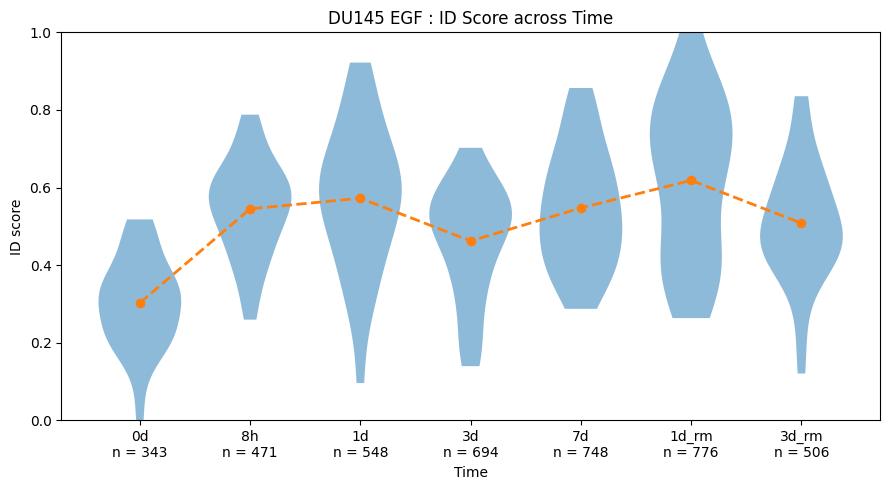

In [32]:
# ------------------------------------------------------------
# Prepare groups in dose order
# ------------------------------------------------------------

time_order = ["0d", "8h", "1d", "3d", "7d", "1d_rm", "3d_rm"]

id_summary = (
    id_summary
    .set_index('Time')
    .loc[time_order]
    .reset_index()
)

id_groups = [
    id_long.loc[id_long["Time"] == time, "ID"].values
    for time in time_order
]

id_means = [
    np.mean(group)
    for group in id_groups
]

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5))

positions = np.arange(len(time_order))

# Violin plots
parts = ax.violinplot(
    id_groups,
    positions=positions,
    widths=0.75,
    showmeans=False,
    showmedians=False,
    showextrema=False
)

# Make violins slightly transparent
for body in parts["bodies"]:
    body.set_alpha(0.5)

# ------------------------------------------------------------
# Dashed line connecting mean ID scores
# ------------------------------------------------------------

ax.plot(
    positions,
    id_means,
    linestyle="--",
    marker="o",
    linewidth=2,
    markersize=6
)

# ------------------------------------------------------------
# X-axis labels: dose + number of cells
# ------------------------------------------------------------

labels = [
    f"{time}\nn = {cell_counts.loc[time]}"
    for time in time_order
]

ax.set_xticks(positions)
ax.set_xticklabels(labels)

# ------------------------------------------------------------
# Labels / formatting
# ------------------------------------------------------------

ax.set_xlabel("Time")
ax.set_ylabel("ID score")
ax.set_ylim(0, 1)

ax.set_title("DU145 EGF : ID Score across Time")

plt.tight_layout()
plt.show()

Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
    0d     1d   0.2696    0.0  0.1462  0.3931   True
    0d  1d_rm   0.3157    0.0  0.1922  0.4392   True
    0d     3d   0.1596 0.0025  0.0362  0.2831   True
    0d  3d_rm   0.2054    0.0  0.0819  0.3288   True
    0d     7d   0.2447    0.0  0.1212  0.3681   True
    0d     8h   0.2424    0.0  0.1189  0.3659   True
    0d  8h_rm    0.178 0.0004  0.0546  0.3015   True
    1d  1d_rm    0.046 0.9472 -0.0774  0.1695  False
    1d     3d    -0.11 0.1204 -0.2335  0.0135  False
    1d  3d_rm  -0.0643 0.7545 -0.1878  0.0592  False
    1d     7d   -0.025 0.9986 -0.1485  0.0985  False
    1d     8h  -0.0273 0.9976 -0.1507  0.0962  False
    1d  8h_rm  -0.0916 0.3153 -0.2151  0.0319  False
 1d_rm     3d   -0.156 0.0036 -0.2795 -0.0326   True
 1d_rm  3d_rm  -0.1103 0.1181 -0.2338  0.0132  False
 1d_rm     7d   -0.071 0.6483 -0.1945  0.0525 

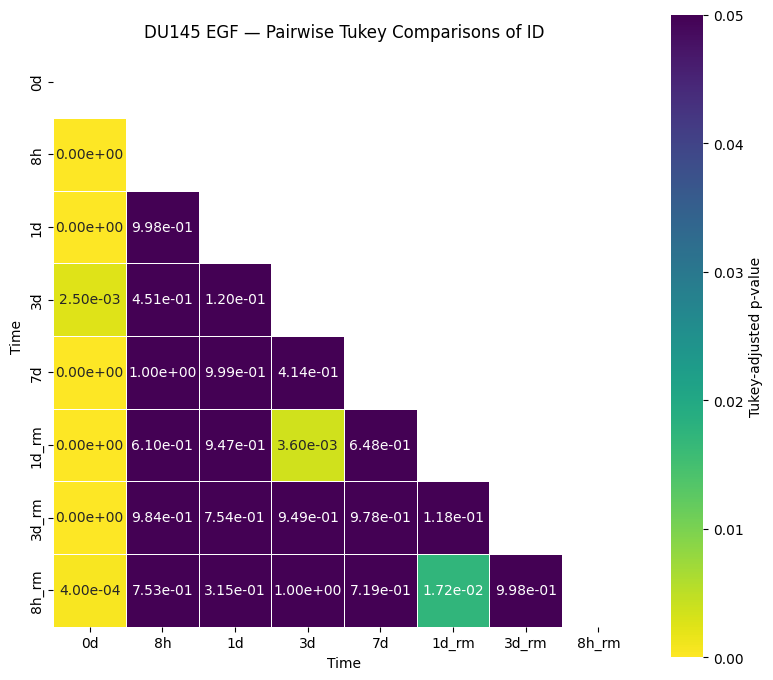

In [33]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# ============================================================
# TUKEY TEST
# ============================================================

tukey = pairwise_tukeyhsd(
    endog=id_long["ID"],
    groups=id_long["Time"],
    alpha=0.05
)

print(tukey)


# ============================================================
# TIME ORDER
# ============================================================

time_order = [
    "0d",
    "8h",
    "1d",
    "3d",
    "7d",
    "1d_rm",
    "3d_rm"
]


# ============================================================
# EXTRACT TUKEY RESULTS
# ============================================================

tukey_df = pd.DataFrame(
    data=tukey._results_table.data[1:],
    columns=tukey._results_table.data[0]
)

# Make sure p-adj is numeric
tukey_df["p-adj"] = tukey_df["p-adj"].astype(float)


# ============================================================
# CREATE SYMMETRIC P-ADJ MATRIX
# ============================================================

tukey_matrix = pd.DataFrame(
    np.nan,
    index=time_order,
    columns=time_order
)


for _, row in tukey_df.iterrows():

    group1 = row["group1"]
    group2 = row["group2"]
    p_adj = row["p-adj"]

    tukey_matrix.loc[group1, group2] = p_adj
    tukey_matrix.loc[group2, group1] = p_adj


# ============================================================
# HEATMAP
# LOWER TRIANGLE ONLY
# ============================================================

mask = np.triu(
    np.ones_like(tukey_matrix, dtype=bool)
)


plt.figure(figsize=(8, 7))

sns.heatmap(
    tukey_matrix,
    mask=mask,
    annot=True,
    fmt=".2e",
    cmap="viridis_r",
    vmin=0,
    vmax=0.05,
    linewidths=0.5,
    square=True,
    cbar_kws={
        "label": "Tukey-adjusted p-value"
    }
)

plt.title(
    "DU145 EGF — Pairwise Tukey Comparisons of ID"
)

plt.xlabel("Time")
plt.ylabel("Time")

plt.tight_layout()
plt.show()